# Проект. Исследование стартапов
- Автор: Тоскина Ульяна Алексеевна
- Дата: 12.03.2026

## Введение

Венчурные инвестиции играют важную роль в развитии технологических компаний и стартапов. Для инвесторов важно понимать, как меняется рынок финансирования со временем, какие сегменты растут наиболее активно, а также какие типы инвестиций оказываются наиболее эффективными.
В рамках данного проекта проводится анализ данных о финансировании компаний. Исследование направлено на выявление ключевых тенденций рынка: динамики инвестиционной активности, структуры финансирования и эффективности различных типов инвестиций.

Цель исследования — проанализировать структуру и динамику финансирования компаний, а также определить наиболее перспективные сегменты и типы инвестиций.

Для достижения этой цели были поставлены следующие задачи:
- провести предобработку и очистку данных
- проанализировать структуру финансирования компаний
- выделить сегменты рынка и определить их масштаб
- исследовать популярность и объём различных типов финансирования
- изучить динамику инвестиционной активности по годам
- определить сегменты рынка, демонстрирующие рост
- оценить долю возвращённых средств по типам инвестиций
- на основе проведенного анализа сформулировать рекомендации для инвесторов

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.


### 1.1. Вывод общей информации


In [ ]:
# Загрузим необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt

Загрузим предоставленные датасеты.

In [ ]:
# Загрузим основной датасет в датафрейм cb_investments
cb_investments = pd.read_csv("", sep=';', low_memory=False)

# Загрузим дополнительный датасет в датафрейм cb_returns
cb_returns = pd.read_csv("")

Ознакомимся с данными: с их размерами, названиями, типами данных и представлениями.

In [ ]:
# Выведем общую информацию об обоих датафреймах
cb_investments.info(), cb_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

(None, None)

Посмотрим, как выглядят первые строки датафреймов.

In [ ]:
# Выведем первые строки данных об инвестициях
cb_investments.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Выведем первые строки данных о возвратах
cb_returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [ ]:
# Посчитаем количество пропусков в основном датафрейме
cb_investments.isna().sum()

name                     4857
homepage_url             8305
category_list            8817
 market                  8817
 funding_total_usd       4856
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15740
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4856
mid_funding_at          24006
last_funding_at          4856
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_A                  4856
round_B   

In [ ]:
# Посчитаем долю пропусков в основном датафрейме
cb_investments.isna().sum()/cb_investments.shape[0] * 100

name                     8.945740
homepage_url            15.296350
category_list           16.239363
 market                 16.239363
 funding_total_usd       8.943898
status                  11.364055
country_code            18.655837
state_code              44.448742
region                  18.655837
city                    20.208494
funding_rounds           8.943898
participants            43.874093
founded_at              28.990312
founded_month           29.122923
founded_quarter         29.122923
founded_year            28.990312
first_funding_at         8.943898
mid_funding_at          44.214830
last_funding_at          8.943898
seed                     8.943898
venture                  8.943898
equity_crowdfunding      8.943898
undisclosed              8.943898
convertible_note         8.943898
debt_financing           8.943898
angel                    8.943898
grant                    8.943898
private_equity           8.943898
post_ipo_equity          8.943898
post_ipo_debt 

Основной датасет `cb_investments` состоит из 54294 строк и 40 столбцов, дополнительный `cb_returns` - из 15 строк и 14 столбцов.
Названия столбцов ` market` и ` funding_total_usd` имеют лишние пробелы, что неудобно для работы с ними - нужно привести к единому стилю.
Не все типы данных соответсвуют содержимому столбцов:
- ` funding_total_usd` имеет тип `object`, а должен быть числовым. По первым строкам датафрейма можно выявить проблему - в этом столбце в качестве разделителя используется запятая.
- Столбцы с датами, а именно: `founded_at`, `founded_month`, `founded_quartal`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, представлены типом object. Их нужно будет привести к формату дат.

В столбцах `state_code`, `participants` и `mid_funding_at` много пропущенных значений - около 44%. А также в четырех столбцах с датами пропущенно около 29%.

У целой группы столбцов одинаковое количество пропусков (примерно 8,9%). Такая повторяемость может указывать на строки, в которых практически отсутсвует ключевая для анализа информация. На этапе предобработки нужно отдельно оценить, есть ли смысл сохранять такие записи.

В дополнительном датасете проблем на данном этапе не наблюдается: пропуски отсутствуют, названия отражают суть, типы данных верные.

Данные, в целом, подходят для дальнейшего анализа, но основной датасет требует предобработки: нужно исправить названия столбцов, привести к подходящим типам данных и обработать пропуски.

### 1.2. Предобработка данных

Посмотрим отдельно на названия столбцов в датафреймах.

In [ ]:
# Выведем названия столбцов cb_investments и cb_returns
cb_investments.columns, cb_returns.columns

(Index(['name', 'homepage_url', 'category_list', ' market ',
        ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
        'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
        'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
        'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
        'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
        'private_equity', 'post_ipo_equity', 'post_ipo_debt',
        'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
        'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
       dtype='object'),
 Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
        'convertible_note', 'debt_financing', 'angel', 'grant',
        'private_equity', 'post_ipo_equity', 'post_ipo_debt',
        'secondary_market', 'product_crowdfunding'],
       dtype='object'))

Для дальнейшей оценки сохраним исходное количество строк в основном датафрейме.

In [ ]:
# Сохраним исходное количество строк cb_investments
rows = cb_investments.shape[0]

Избавимся от лишних пробелов в названиях столбцов.

In [ ]:
# Удалим пробелы в названиях столбцов
cb_investments.columns = cb_investments.columns.str.strip()
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [ ]:
# Изучим значения, которые встречаются в столбце cb_investments
cb_investments['funding_total_usd'].sort_values().unique()[:10]

array([' -   ', ' 1 ', ' 1,00,00,00,000 ', ' 1,00,00,000 ',
       ' 1,00,00,001 ', ' 1,00,00,002 ', ' 1,00,00,003 ', ' 1,00,00,006 ',
       ' 1,00,00,008 ', ' 1,00,000 '], dtype=object)

Столбец `funding_total_usd` представлен типом `object`, хотя содержит числовые значения, из-за использования запятой как разделителя. А также обнаружена запись ` -   `, судя по всему обозначающая пропуск. Обработаем данный столбец:
 - избавимся от запятых в качетсве разделителя
 - удалим лишние пробелы в записях
 - заменим `-`, который указывает на отсутствие значения, на `NaN`
 - преобразуем тип данных в числовой

In [ ]:
# Методом replace() удалим запятые
cb_investments['funding_total_usd'] = cb_investments['funding_total_usd'].str.replace(',', '')
# Удалим лишние пробелы в записях
cb_investments['funding_total_usd'] = cb_investments['funding_total_usd'].str.strip()
# Заменим - на NaN
cb_investments['funding_total_usd'] = cb_investments['funding_total_usd'].replace('-', pd.NA)
# Приведем к числовому типу
cb_investments['funding_total_usd'] = pd.to_numeric(cb_investments['funding_total_usd'])
# Выведем результат
cb_investments['funding_total_usd'].dtype, cb_investments['funding_total_usd'].sort_values().unique()[:20]

(dtype('float64'),
 array([  1.,  14.,  22.,  30.,  50.,  60.,  80., 100., 102., 118., 123.,
        144., 150., 215., 291., 300., 317., 400., 428., 500.]))

Еще раз проверим типы данных столбцов, которые хранят значения даты и времени.

In [ ]:
# Выведем типы данных столбцов с датами
cb_investments[['founded_at', 'founded_month', 'founded_quarter', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].dtypes

founded_at          object
founded_month       object
founded_quarter     object
first_funding_at    object
mid_funding_at      object
last_funding_at     object
dtype: object

Теперь приведем к типу даты и времени те столбцы, где хранятся полные даты: `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`. При попытке напрямую привести их к типу даты и времени выяснилось, что в данных встречаются некорректные значения, поэтому при преобразовании используем параметр `errors = 'coerce'`, чтобы некорректные значения станут пропусками.
Столбцы `founded_month` и `founded_quarter` также содержат информацию о времени основания компании, но они записаны в нестандартных форматах для `pd.to_datetime()` и не используются в последующем анализе, поэтому оставим их без преобразований.

In [ ]:
# Приведем столбцы с полными датами к типу datetime
cb_investments['founded_at'] = pd.to_datetime(cb_investments['founded_at'], errors = 'coerce')
cb_investments['first_funding_at'] = pd.to_datetime(cb_investments['first_funding_at'], errors = 'coerce')
cb_investments['mid_funding_at'] = pd.to_datetime(cb_investments['mid_funding_at'], errors = 'coerce')
cb_investments['last_funding_at'] = pd.to_datetime(cb_investments['last_funding_at'], errors = 'coerce')

cb_investments[['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].dtypes

founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object

In [ ]:
# Посчитаем количество пропусков после преобразования типов данных
cb_investments[['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].isna().sum()

founded_at          15741
first_funding_at     4866
mid_funding_at      24006
last_funding_at      4862
dtype: int64

Столбцы успешно приведены к типу `datetime64[ns]`. После преобразования число пропусков изменилось, потому что некорректные даты стали пропусками, но их немного, и это не мешает продолжать анализ.

Сделаем столбец `year` индексом датафрейма, чтобы упростить дальнейшую работу с данными по годам.

In [ ]:
# Используем столбец year в качестве индекса
cb_returns = cb_returns.set_index('year')
cb_returns.index.name

'year'

В текстовых столбцах могут встречаться лишние пробелы в начале и конце строк. Удалим их.

In [ ]:
# Удалим лишние пробелы в значениях текстовых столбцов
text_columns = ['name', 'homepage_url', 'category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']
for column in text_columns:
    cb_investments[column] = cb_investments[column].str.strip()

В текстовых столбцах присутствуют пропущенные значения. Заполним пропуски заглушкой `unknown`. Столбцы `name` и `homepage_url` оставим без изменений.

In [ ]:
# Заполним пропуски заглушкой unknown
cb_investments['category_list'] = cb_investments['category_list'].fillna('unknown')
cb_investments['market'] = cb_investments['market'].fillna('unknown')
cb_investments['status'] = cb_investments['status'].fillna('unknown')
cb_investments['country_code'] = cb_investments['country_code'].fillna('unknown')
cb_investments['state_code'] = cb_investments['state_code'].fillna('unknown')
cb_investments['region'] = cb_investments['region'].fillna('unknown')
cb_investments['city'] = cb_investments['city'].fillna('unknown')
cb_investments[['category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']].isna().sum()

category_list    0
market           0
status           0
country_code     0
state_code       0
region           0
city             0
dtype: int64

Найдем и удалим полные дубликаты в датафреймах.

In [ ]:
# Посчитаем количество полных дубликатов
cb_investments.duplicated().sum(), cb_returns.duplicated().sum()

(4855, 0)

В дополнительном датасете полных дубликатов нет, а вот в основном 4855 полностью повторяющихся строк. Такие записи не несут в себе важной информации и могут исказить результаты анализа - удалим их.

In [ ]:
# Удалим полные дубликаты
cb_investments = cb_investments.drop_duplicates()
cb_investments.duplicated().sum()

0

Удаление полных дубликатов в датафрейме прошло успешно.

Проверим количество пропущенных значений в столбце `funding_total_usd`.

In [ ]:
# Посчитаем пропущенные значения
cb_investments['funding_total_usd'].isna().sum()

8532

В столбце `funding_total_usd` 8532 пропущенных значения. Эти строки не содержат информации об объеме инвестиций и не могут использоваться в дальнейшем анализе. Удалим такие записи из датасета.

In [ ]:
# Удалим пропуски
cb_investments = cb_investments.dropna(subset = ['funding_total_usd'])
cb_investments['funding_total_usd'].isna().sum()

0

Посчитаем количество пропусков в столбце `mid_funding_at`.

In [ ]:
# Посчитаем количество пропусков
cb_investments['mid_funding_at'].isna().sum()

13676

Обнаружено 13676 пропусков. Заполним их серединой интервала между датами `first_funding_at` и `last_funding_at`.

In [ ]:
# Заполним столбец средним значением
cb_investments['mid_funding_at'] = cb_investments['mid_funding_at'].fillna(cb_investments['first_funding_at'] + (cb_investments['last_funding_at'] - cb_investments['first_funding_at']) / 2)
cb_investments['mid_funding_at'].isna().sum()

1

После заполнения пропущенных значений в столбце остался только один пропуск. Возможно, для этой строки отсутствуют значения в одном или обоих столбцах с датами, поэтому вычислить середину интервала невозможно.

Посмотрим, как изменился исходный датасет.

In [ ]:
# Посчитаем строки
rows_2 = cb_investments.shape[0]
removed_count = rows - rows_2
removed_percent = (rows - rows_2) / rows * 100

print(f'Исходное количество строк: {rows}\nПолученное количество строк: {rows_2}\nУдалено строк: {removed_count}\nПроцент удаленных строк: {round(removed_percent, 2)}')

Исходное количество строк: 54294
Полученное количество строк: 40907
Удалено строк: 13387
Процент удаленных строк: 24.66


Всего было удалено 13387 строк, что составляет 24,66% от исходного объема данных. Несмотря на это, в датасете осталось 40907 строк, что является достаточно большим объемом данных для проведения дальнейшего анализа.

In [ ]:
cb_investments.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 40907 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40906 non-null  object        
 1   homepage_url          38593 non-null  object        
 2   category_list         40907 non-null  object        
 3   market                40907 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                40907 non-null  object        
 6   country_code          40907 non-null  object        
 7   state_code            40907 non-null  object        
 8   region                40907 non-null  object        
 9   city                  40907 non-null  object        
 10  funding_rounds        40907 non-null  float64       
 11  participants          27331 non-null  float64       
 12  founded_at            32200 non-null  datetime64[ns]
 13  founded_month   

На этапе предобработки данных были выполнены следующие действия:
- Названия столбцов приведены к единому стилю - удалены лишние пробелы.
- Столбец `funding_total_usd` очищен от разделителей разрядов и пробелов, преобразован в числовой тип данных.
- Столбцы с полными датами приведены к типу `datetime`, некорректные даты преобразованы в пропуски.
- Пропущенные значения в текстовых столбцах заполнены заглушкой `unknown`.
- Обнаружено и удалено 4855 полных дубликатов.
- Удалено 8532 строки, не содержащие информации об объеме финансирования.
- Пропущенные значения в столбце `mid_funding_at` заполнены серединой интервала между датами первого и последнего финансирования. Остался только один пропуск.

В результате предобработки было удалено 24,66% строк от исходного датасета. Полученный датасет остается достаточно большим и готов для дальнейшего анализа финансирования.

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Для разделения компаний на группы по срокам финансирования, сначала рассчитаем длительность периода финансирования.

In [ ]:
# Посчитаем сроки финансирования
cb_investments['funding_duration'] = cb_investments['last_funding_at'] - cb_investments['first_funding_at']
cb_investments['funding_duration_days'] = cb_investments['funding_duration'].dt.days
cb_investments[['first_funding_at', 'last_funding_at', 'funding_duration', 'funding_duration_days']].head()

,first_funding_at,last_funding_at,funding_duration,funding_duration_days
0,2014-01-06,2014-01-06,0 days,0.0
1,2014-05-15,2014-05-15,0 days,0.0
2,2009-07-02,2009-07-02,0 days,0.0
3,2013-11-21,2014-11-03,347 days,347.0
4,2014-01-14,2014-01-14,0 days,0.0


In [ ]:
# Создадим функцию распределения по группам финансирования
def funding_group(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif row['funding_duration_days'] <= 365:
        return 'Срок финансирования до года'
    else:
        return 'Срок финансирования более года'

In [ ]:
# Применим функцию funding_group к датафрейму
cb_investments['funding_group'] = cb_investments.apply(funding_group, axis = 1)
cb_investments['funding_group'].value_counts()

Единичное финансирование          24113
Срок финансирования более года    12293
Срок финансирования до года        4501
Name: funding_group, dtype: int64

In [ ]:
# Установим порядок и цвета для будущих графиков
order = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года']
colors = {
    'Единичное финансирование': '#5875A4',
    'Срок финансирования до года': '#CC8963',
    'Срок финансирования более года': '#5F9E6E'
}

In [ ]:
# Посчитаем долю компаний в каждой группе
group_counts = cb_investments['funding_group'].value_counts(normalize = True) * 100
group_counts = group_counts.reindex(order)
group_counts

Единичное финансирование          58.945902
Срок финансирования до года       11.003007
Срок финансирования более года    30.051092
Name: funding_group, dtype: float64

Визуализируем соотношение этих групп.

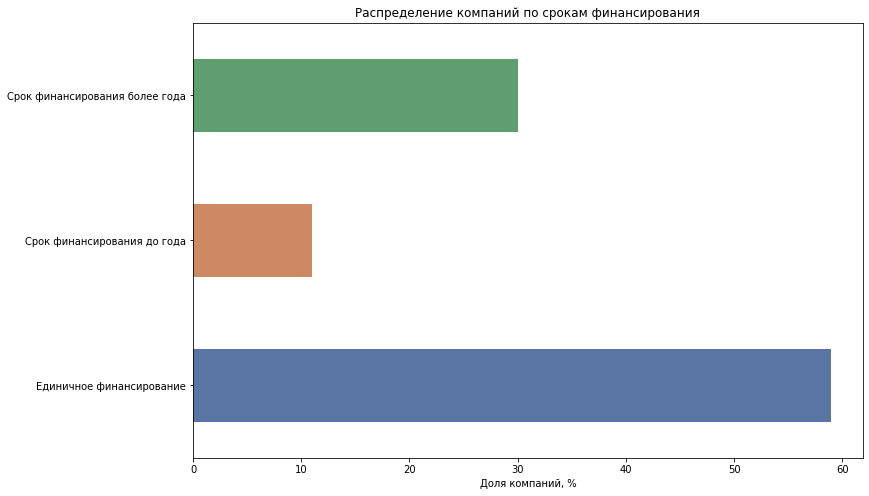

In [ ]:
# Построим график распределения долей компаний по срокам финансирования
group_counts.plot(kind = 'barh',
                 color = [colors[i] for i in group_counts.index],
                 figsize = (12, 8))

plt.title('Распределение компаний по срокам финансирования')
plt.ylabel('')
plt.xlabel('Доля компаний, %')

plt.show()

Теперь посмотрим на распределение общего объема привлеченных инвестиций между группами компаний.

In [ ]:
# Найдем абсолютное и относительное значение объемов инвестиций по группам
funding_sum = cb_investments.groupby('funding_group')['funding_total_usd'].sum()
funding_share = funding_sum / funding_sum.sum()
funding_share = funding_share.reindex(order)
funding_share

funding_group
Единичное финансирование          0.306182
Срок финансирования до года       0.075101
Срок финансирования более года    0.618716
Name: funding_total_usd, dtype: float64

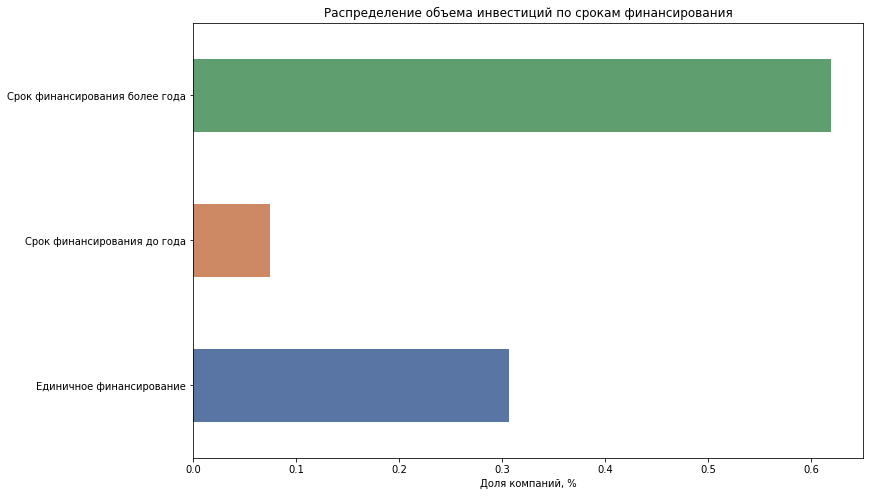

In [ ]:
# Построим график распределения объема инвестиций по срокам финансирования
funding_share.plot(kind = 'barh',
                 color = [colors[i] for i in group_counts.index],
                 figsize = (12, 8))

plt.title('Распределение объема инвестиций по срокам финансирования')
plt.ylabel('')
plt.xlabel('Доля компаний, %')

plt.show()

Большинство компаний (59%) получают только один раунд финансирования. Компании с периодом финансирования более года составляют около 30% выборки, а компании со сроком финансирования до года - около 11%.

Однако распределение объемов инвестиций отличается от рапределения компаний. Несмотря на то, что компании с едичиным раундом составляют большинство, на них приходится лишь около 31% общего объема инвестиций. Наибольшая доля инвестиций (62%) приходится на компании, которые привлекали финансирование более года. Компании со сроком финансирования до года получают наименьшую долю средств - 7,5%.

Это говорит о том, что более длительные циклы финансирования характерны для компаний, которые привлекают значительно больший объем инвестиций.

Инвестору стоит иметь в виду, что наиболее устойчивые проекты часто проходят несколько раундов финансирования, поэтому компании с более длительной историей привлечения инвестиций могут рассматриваться как более зрелыеи устойчивые.

### 2.2 Выделение средних и нишевых сегментов рынка

Определим, как часто каждый сегмент рынка встречается в датасете - посчитаем количество компаний в каждом значении столбца `market`.

In [ ]:
# Посчитаем количество компаний в каждом сегменте
market_counts = cb_investments['market'].value_counts()
market_counts.head()

Software         4812
Biotechnology    3590
unknown          2503
Mobile           2344
E-Commerce       1866
Name: market, dtype: int64

Разделим сегменты рынка на группы по количеству компаний.

In [ ]:
# Выделим сегменты по категориям
mass_market = market_counts[market_counts > 120]
mid_market = market_counts[(market_counts >= 35) & (market_counts <= 120)]
niche_market = market_counts[market_counts < 35]

len(mass_market), len(mid_market), len(niche_market)

(49, 57, 289)

Построим график распределения количества компаний по сегментам рынка, отметим границы нишевых и средних сегментов. Также ограничим график сегментами, в которых не более 200 компаний, так как большинство сегментов находится именно в этом диапазоне.

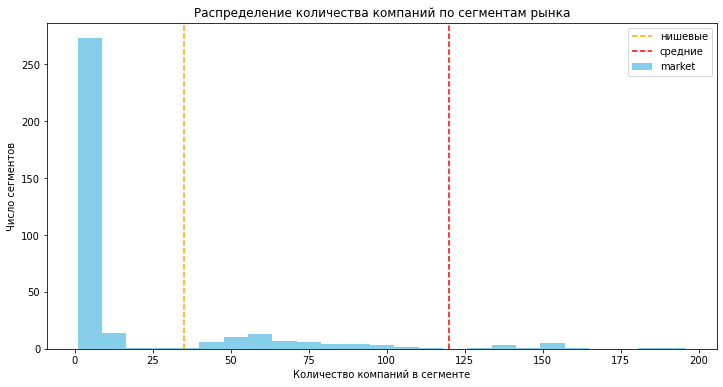

In [ ]:
# Построим график распределения компаний по сегментам рынка
market_counts[market_counts <= 200].plot(kind = 'hist',
                                         bins = 25,
                                         figsize = (12,6),
                                         color = 'skyblue')

plt.axvline(35, color = 'orange', linestyle = '--', label = 'нишевые')
plt.axvline(120, color = 'red', linestyle = '--', label = 'средние')
plt.title('Распределение количества компаний по сегментам рынка')
plt.xlabel('Количество компаний в сегменте')
plt.ylabel('Число сегментов')
plt.legend()

plt.show()

Наибольшая часть сегментов относится к нишевым - число компаний в них невелико. Значительно меньше сегментов относятся к средним, а массовые встречаются еще реже.

Многие компании работают в узких специализированных нишах, тогда как крупные массовые сегменты представлены меньшим количеством направлений:
- массовых сегментов - 49
- средних - 57
- нишевых - 289.

Заменим средние сегменты на общую категорию `mid`, а нишевые - на `niche`.

In [ ]:
# Заменим средние и нишевые сегменты на общие категории и проверим результат
cb_investments.loc[cb_investments['market'].isin(mid_market.index), 'market'] = 'mid'
cb_investments.loc[cb_investments['market'].isin(niche_market.index), 'market'] = 'niche'
cb_investments['market'].value_counts().head()

Software         4812
mid              3841
Biotechnology    3590
unknown          2503
Mobile           2344
Name: market, dtype: int64

После замены в столбце `market` в исходном виде сохранились только массовые сегменты, а все средние и нишевые были объединены в два общих сегмента. Это упрощает дальнейший анализ и позволяет сосредоточиться на крупных сегментах рынка, не рассматривая отдельно много численные редкие направления.

Еще стоит отметить, что в массовые сегменты попала категория `unknown` - у многих компаний сегмент не указан.

На этапе инжиниринга признаков были сформированы дополнительные характеристики для более подробного анализа финансирования.

Компании были разделены на группы по длительности периода финансирования: единичное финансирование, сроком до одного года и финансирование более года. Большинство компаний получают финансирование только в одном раунде, однако значительная доля общего объема инвестиций приходится на компании с более длительным периодом привлечения средств.

Также были рассмотрены сегменты рынка. Большинство сегментов являются нишевыми и содержат небольшое число компаний. Для упрощения дальнейшей работы сегменты были укрупнены: нишевые и средние сегменты объединены в категории `mid` и `niche` массовые сегменты сохранены в исходном виде.

Проведенная подготовка данных позволяет перейти к исследованию выбросов и структуры финансирования компаний.

Полученные результаты показывают, что инвестиционный рынок характеризуется высокой концентрацией активности в нескольких крупных сегментах и вокруг определённых инструментов финансирования. Для инвестора это означает, что при выборе объектов инвестирования стоит уделять внимание компаниям из наиболее развитых сегментов рынка и учитывать стадию развития компании, отражённую в структуре её финансирования.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся.

Посмотрим на распределение общего объема инвестиций и оценим диапазон тичиных значений.

In [ ]:
# Выведем статистику инвестиций
cb_investments['funding_total_usd'].describe()

count    4.090700e+04
mean     1.591253e+07
std      1.686788e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

По статистике видно, что распределение объема инвестиций сильно асимметрично.
Медианное значение составляет около 2 млн., а 75% компаний привлекли не более 10 млн..

При это максимальное значение превышает 30 млрд., что сильно больше типичных значений. Это указывает на наличие значительных выбросов в данных.

Чтобы лучше рассмотреть распределение основной массы значений, построим boxplot без отображения выбросов.

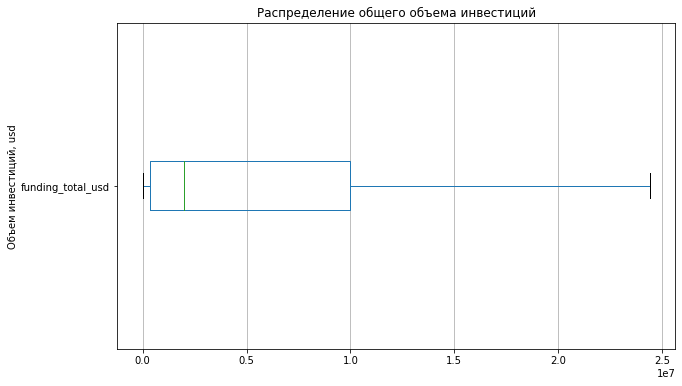

In [ ]:
# Построим boxplot для общего объема инвестиций
cb_investments.boxplot(column = 'funding_total_usd',
                       figsize = (10,6),
                       vert = False,
                       showfliers = False)

plt.title('Распределение общего объема инвестиций')
plt.ylabel('Объем инвестиций, usd')
plt.grid(False, axis = 'y')

plt.show()

Распределение общего объема инвестиций сильно асимметрично и имеет длинный правый хвост. Основная часть компаний получает небольшие инвестиции, а небольшая часть - значительно более крупные суммы.

Типичный диапазон значений можно определить по межквартильному интервалу: от 350к (первый квартиль) до 10 млн. (третий квартиль).

Значения, значительно превышающие этот диапазон, можно рассматривать как потенциальные выбросы. Максимальное значение превышает 30 млрд. долларов, что на несколько порядков больше типичных значений и подтверждает наличие аномально крупных инвестиций.

Используем метод межквартильного размаха IQR для определения аномальных значений объема финансирования. Структура финансирования может различаться между сегментами рынка, рассчитаем границы отдельно для каждого сегмента.

In [ ]:
# Создадим новый столбец для выбросов
cb_investments['outliers'] = False

In [ ]:
# Определим компании с аномальным объемом общего финансирования
for segment in cb_investments['market'].unique():
    data = cb_investments[cb_investments['market'] == segment]['funding_total_usd']

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    out = ((cb_investments['market'] == segment) &
           ((cb_investments['funding_total_usd'] < lower_bound) |
           (cb_investments['funding_total_usd'] > upper_bound)))
    cb_investments.loc[out, 'outliers'] = True

In [ ]:
# Посмотрим количество выбросов
cb_investments['outliers'].sum()

5244

In [ ]:
# Найдем долю выбросов по сегментам
outliers_share = cb_investments.groupby('market')['outliers'].mean().sort_values(ascending = False)
outliers_share.head(10)

market
Real Estate        0.172043
Entertainment      0.166667
Consulting         0.166189
Search             0.164948
Cloud Computing    0.164474
Photography        0.161765
SaaS               0.161765
Technology         0.159664
Video              0.159574
niche              0.159036
Name: outliers, dtype: float64

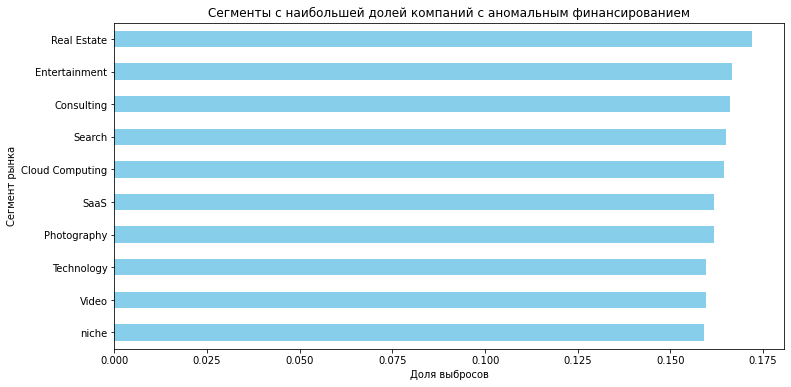

In [ ]:
# Построим визуализацию топ-10 аномальных сегментов
outliers_share.head(10).sort_values().plot(kind = 'barh',
                                          figsize = (12, 6),
                                          color = 'skyblue')

plt.title('Сегменты с наибольшей долей компаний с аномальным финансированием')
plt.xlabel('Доля выбросов')
plt.ylabel('Сегмент рынка')

plt.show()

Для выявления аномальных значений объема финансирования был использован метод межквартильного размаха IQR. Границы выбросов рассчитывались отдельно для каждого сегмента. В результате анализа выявлено 5244 компании с аномальным объемом общего финансирования.

Наибольшая доля компаний с аномальным финансированием наблюдается в сегментах: Real Estate, Entertainment, Consulting, Search и Cloud Computing, где доля выбросов составляет примерно 16-17%.
Это может говорить о том, что в данных сегментах встречаются отдельные компании, которые привлекают значительно более крупные инвестиции по сравнению с большинством компаний внутри этих сегментов.

Стоит отметить, что категория `niche` также попала в топ-10, что может быть связано с тем, что в узких сегментах отдельные крупные инвестиции сильнее выделяются на фоне небольшого числа инвестиций.

Проверим, можно ли считать данные за 2014 год полными. Посмотрим распределение количества раундов финансирования по годам.

In [ ]:
# Создадим столбец с годом финансирования и посчитаем количество раундов для каждого
cb_investments['funding_year'] = cb_investments['mid_funding_at'].dt.year
rounds_by_year = cb_investments.groupby('funding_year')['funding_rounds'].sum()
rounds_by_year

funding_year
1921.0        1.0
1960.0        2.0
1979.0        1.0
1982.0        3.0
1983.0        1.0
1984.0        2.0
1985.0        3.0
1987.0        2.0
1989.0        1.0
1990.0        1.0
1992.0        5.0
1993.0        1.0
1994.0        4.0
1995.0        9.0
1996.0       11.0
1997.0       13.0
1998.0       28.0
1999.0      118.0
2000.0      247.0
2001.0      163.0
2002.0      164.0
2003.0      260.0
2004.0      410.0
2005.0     1446.0
2006.0     2914.0
2007.0     4845.0
2008.0     6024.0
2009.0     7003.0
2010.0     8266.0
2011.0     9248.0
2012.0    11354.0
2013.0    14276.0
2014.0     7757.0
Name: funding_rounds, dtype: float64

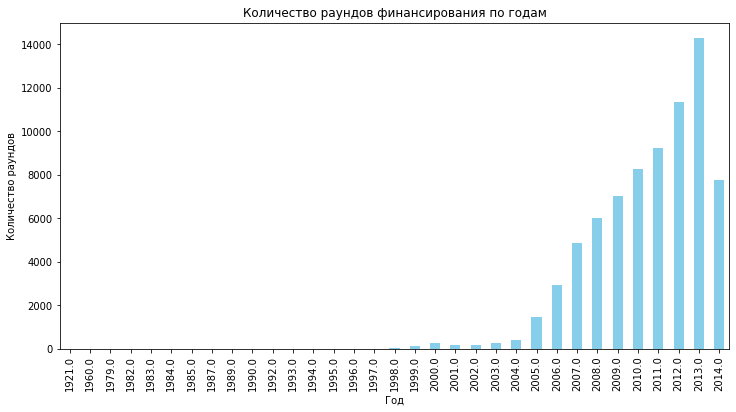

In [ ]:
# Визуализируем динамику
rounds_by_year.plot(kind = 'bar',
                    figsize = (12, 6),
                    color = 'skyblue')

plt.title('Количество раундов финансирования по годам')
plt.xlabel('Год')
plt.ylabel('Количество раундов')

plt.show()

Основная активность количества раундов финансирования начинается с конца 1990-ых годов и значительно увеличивается после 2005 года. Количество раундов стабильно растет вплоть до 2013 года, который является пиковым.

В 2014 году проиходит заметное снижение количества раундов финансирования по сравнению с 2013 годом (7757 против 14276 раундов). Это может свидетельствовать о том, что данные за 2014 год представлены не полностью.

Тем не менее, объем данных за 2014 год остается достаточно большим, поэтому год можно учитывать в даальнейшем анализе, однако следует иметь в виду возможную неполноту данных.

Компании с аномальным объемом финансирования могут исказить результаты анализа, исключим их.

In [ ]:
# Оставим в датасете только компании без выбросов
cb_investments = cb_investments[cb_investments['outliers'] == False]
cb_investments.shape

(35663, 45)

В датасетет без выбросов осталось 35 663 строк.
Теперь оставим в нем только те годы, в которых было зафиксировано не менее 50 раундов финансирования.

In [ ]:
# Определим годы, в которых было не менее 50 раундов и оставим в датасете только их
active_years = rounds_by_year[rounds_by_year >= 50].index
cb_investments = cb_investments[cb_investments['funding_year'].isin(active_years)]
cb_investments.shape

(35616, 45)

После данной фильтрации в датасете осталось 35 616 компаний.
Сформирован очищенный набор данных, содержащий компании с типичными значениями финансирования и относящиеся к периоду с достаточной инвестиционной активностью для более надежного и устойчивого дальнейшего анализа.

### 3.3. Анализ типов финансирования по объёму и популярности


Изучим суммарный объем инвестиций по каждому типу финансирования.

In [ ]:
# Выделим столбцы с типами финансирования и посчитаем общий объем инвестиций для каждого
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']
funding_sum = cb_investments[funding_types].sum().sort_values(ascending = False)
funding_sum

venture                 1.291684e+11
seed                    9.440872e+09
debt_financing          8.178503e+09
private_equity          4.846109e+09
angel                   2.482464e+09
undisclosed             2.138552e+09
grant                   1.978849e+09
post_ipo_equity         1.946452e+09
convertible_note        5.660394e+08
post_ipo_debt           2.867183e+08
equity_crowdfunding     2.379606e+08
product_crowdfunding    1.860939e+08
secondary_market        4.528580e+07
dtype: float64

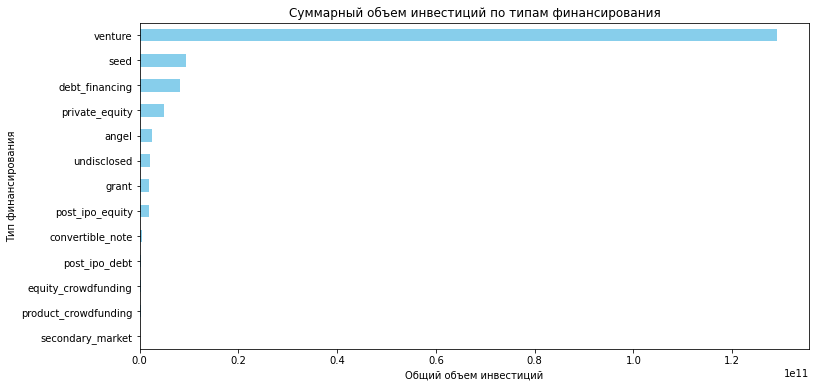

In [ ]:
# Визуализируем результат
funding_sum.sort_values().plot(kind = 'barh',
                 figsize = (12, 6),
                 color = 'skyblue')

plt.title('Суммарный объем инвестиций по типам финансирования')
plt.xlabel('Общий объем инвестиций')
plt.ylabel('Тип финансирования')

plt.show()

Наибольший суммарный объем инвестиций приходится на venture-финансирование, которые значительно превосходит остальные типы.
Существенные объемы также наблюдаются у seed, debt_financing и private_equity, но их значения заметно ниже.
Основной поток инвестиций связан именно с венчурным финансированием, а остальные типы играют более вспомогательную роль.

Посмотрим, как часто используется каждый тип финансирования - сколько компаний привлекали инвестиции каждого типа.

In [ ]:
# Посчитаем количество ненулевых значений
funding_popular = (cb_investments[funding_types] > 0).sum().sort_values(ascending = False)
funding_popular

venture                 18835
seed                    13383
debt_financing           3266
angel                    2940
grant                    1003
undisclosed               817
private_equity            635
convertible_note          521
equity_crowdfunding       515
product_crowdfunding      204
post_ipo_equity           164
post_ipo_debt              27
secondary_market            7
dtype: int64

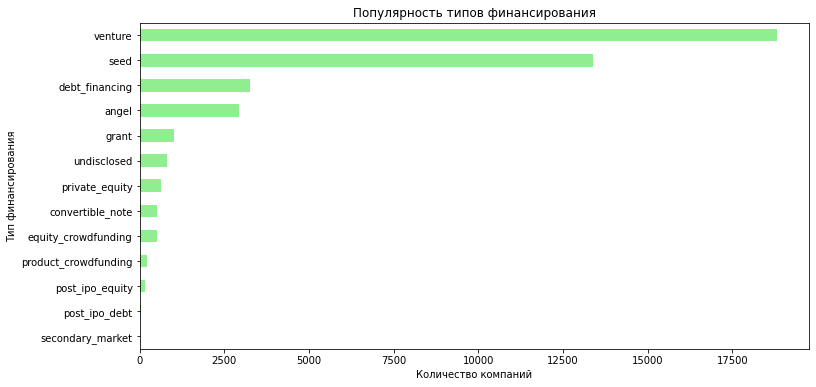

In [ ]:
# Построим график популярности
funding_popular.sort_values().plot(kind = 'barh',
                 figsize = (12, 6),
                 color = 'lightgreen')

plt.title('Популярность типов финансирования')
plt.xlabel('Количество компаний')
plt.ylabel('Тип финансирования')

plt.show()

Чаще всего компании привлекают инвестиции через venture, реже seed, debt_financing и angel. Остальные встречаются заметно реже.

Сравнение объема инвестиций и популярности типов финансирования показывает, что наиболее распространенные типы инвестиций не всегда обеспечивают наибольшие объемы финансирования.
Например, seed и angel используются довольно часто, однако сопровождаются относительно небольшими суммами инвестиций.
В то же время такие типы как private_equity и debt_financing встречаются реже, но имеют более крупные суммы финансирования.

Изучим суммарные объемы возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [ ]:
# Посчитаем суммарные возвраты
returns_sum = cb_returns.sum().sort_values(ascending = False)
returns_sum

venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64

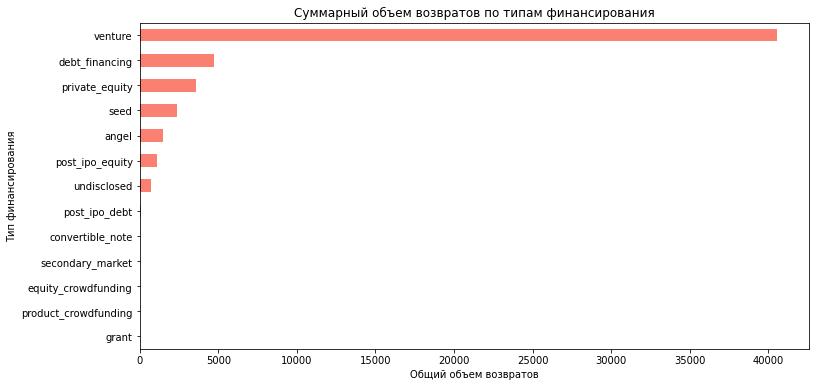

In [ ]:
# Построим график с возвратами
returns_sum.sort_values().plot(kind = 'barh',
                 figsize = (12, 6),
                 color = 'salmon')

plt.title('Суммарный объем возвратов по типам финансирования')
plt.xlabel('Общий объем возвратов')
plt.ylabel('Тип финансирования')

plt.show()

Наибольшие возвраты инвестиций также связаны с venture-финансированием, которое существенно опережает остальные типы. Значительные возвраты наблюдаются также у debt_financing и private_equity.
Наиболее крупные инвестиционные типы не только привлекают большие объемы средств, но и обеспечивают наиболее значительный возврат капитала.

Структура инвестиционного рынка отличается по объему и частоте использования различных типов финансирования.
Наиболее распространенными типами являются `venture` и `seed`, которые активно используются компаниями на ранних стадиях развития. При этом крупнейшие объемы инвестиций и возвратов сосредоточены в венчурном финансировании и типах, связанных с более зрелыми стадиями бизнеса: debt_financing и private_equity.
Ранние стадии инвестирования характеризуются высокой частотой использования и сравнительно небольшими суммами, а более поздние стадии связаны с меньшим количеством сделок, но значительно большими объемами капитала.

Исключение аномально крупных сделок позволяет лучше понять типичную структуру рынка и поведение большинства компаний. Для инвестора это означает, что реальные инвестиционные решения чаще принимаются в диапазоне типичных значений, тогда как экстремально крупные сделки являются скорее исключением и не отражают общие тенденции рынка.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам


Рассчитаем средний объем одного раунда финансирования для каждой компании.

In [ ]:
# Разделим средний объем привлеченных инвестиций на количество раундов в новом столбце
cb_investments['avg_round'] = cb_investments['funding_total_usd']/cb_investments['funding_rounds']
cb_investments[['funding_total_usd', 'funding_rounds', 'avg_round']].head()

,funding_total_usd,funding_rounds,avg_round
1,2000000.0,1.0,2.000000e+06
2,9000000.0,1.0,9.000000e+06
3,7700000.0,3.0,2.566667e+06
4,540000.0,1.0,5.400000e+05
7,8700000.0,1.0,8.700000e+06


Подготовим данные для анализа по годам и визуализируем их.

In [ ]:
# Создадим 2 показателя: типичный размер раунда и их общее количество
stats = cb_investments.groupby('funding_year').agg(median_round = ('avg_round', 'median'),
                                                  total_rounds = ('funding_rounds', 'sum'))
stats

,median_round,total_rounds
funding_year,,
1999.0,2.880000e+06,43.0
2000.0,2.250000e+06,113.0
2001.0,1.570886e+06,66.0
2002.0,3.225000e+06,98.0
2003.0,1.500000e+06,125.0
2004.0,3.000000e+06,181.0
2005.0,4.500000e+06,948.0
2006.0,3.900000e+06,1849.0
2007.0,2.879167e+06,2842.0


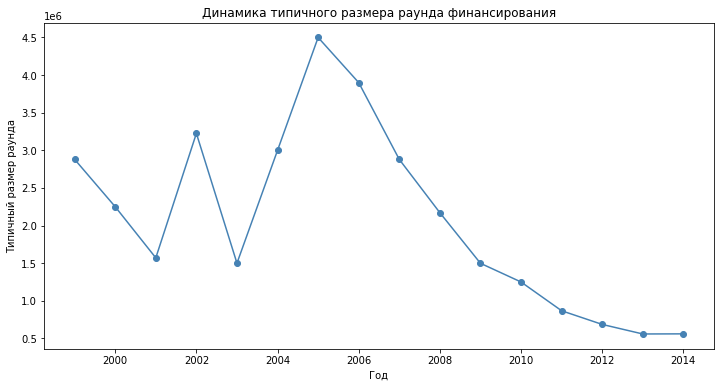

In [ ]:
# Построим график динамики среднего размера раунда
stats['median_round'].plot(kind = 'line',
                          figsize = (12, 6),
                          marker = 'o',
                          color = 'steelblue')

plt.title('Динамика типичного размера раунда финансирования')
plt.xlabel('Год')
plt.ylabel('Типичный размер раунда')

plt.show()

Типичный размер одного раунда со временем менялся. Наибольшее значение наблюдается в 2005 году, когда медианный размер раунда составил около 4,5 млн. долларов. После этого периода типичный размер раунда постепенно уменьшается. Начиная примерно с 2008 года наблюдается устойчивое снижение медианного объема инвестиций в рамках одного раунда.

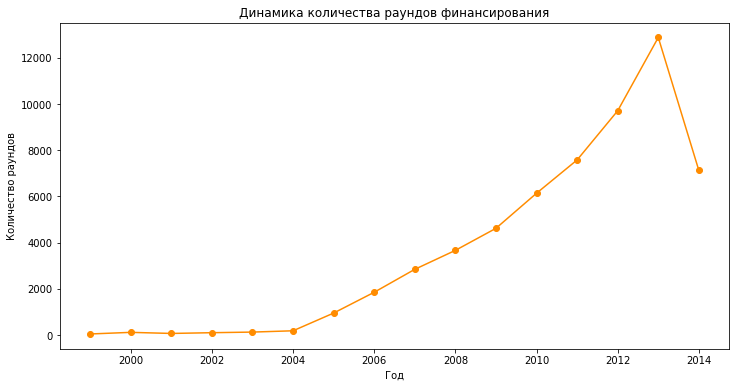

In [ ]:
# Построим график динамики количества раундов
stats['total_rounds'].plot(kind = 'line',
                          figsize = (12, 6),
                          marker = 'o',
                          color = 'darkorange')

plt.title('Динамика количества раундов финансирования')
plt.xlabel('Год')
plt.ylabel('Количество раундов')

plt.show()

Количество раундов финансирования со временем значительно увеличивается. Если в начале рассматриваемого периода количество раундов было небольшим, то, начиная с 2005 года, начинается резкий рост инвестиционной активности. Максимальное количество раундов зафиксировано в 2013 году, после чего в 2014 году происходит заметное снижение.

Сопоставление двух графиков показывает интересную динамику развития инвестиционного рынка. Несмотря на значительное увеличение количества раундов финансирования, типичный размер одного раунда постепенно уменьшается. Это может свидетельствовать о том, что на рынке появляется все больше стартапов, привлекающих относительно небольшие инвестиции.

В 2014 году наблюдается снижение количества раундов финансирования по срарвнению с предыдущим годом. При этом типичный размер одного раунда финансирования остается примерно на уровне 2013 года, но значительно ниже значений середины рассматриваемого периода. Это может быть следствием возможной неполноты данных за 2014 год, как уже было отмечено ранее при анализе полноты данных.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов


Оставим только массовые сегменты и построим сводную таблицу.

In [ ]:
# Исключим категории mid и niche и построим сводную таблицу
mass_data = cb_investments[~cb_investments['market'].isin(['mid', 'niche'])]

pivot_funding = pd.pivot_table(mass_data,
                               index = 'funding_year',
                               columns = 'market',
                               values = 'funding_total_usd',
                               aggfunc = 'sum')
pivot_funding.head()

market,Advertising,Analytics,Apps,Automotive,Big Data,Biotechnology,Clean Technology,Cloud Computing,Consulting,Curated Web,...,Social Media,Social Network Media,Software,Sports,Startups,Technology,Travel,Video,Web Hosting,unknown
funding_year,,,,,,,,,,,,,,,,,,,,,
1999.0,350000.0,10774916.0,NaN,NaN,NaN,NaN,NaN,NaN,115200.0,9250000.0,...,NaN,NaN,29034643.0,NaN,NaN,6000000.0,NaN,NaN,3600000.0,932055.0
2000.0,14470000.0,14822803.0,NaN,NaN,NaN,NaN,NaN,11500000.0,4500000.0,1000000.0,...,NaN,NaN,31732640.0,NaN,NaN,NaN,50230.0,NaN,95343090.0,1839560.0
2001.0,8778321.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305000.0,...,650000.0,NaN,27811352.0,NaN,NaN,22160000.0,NaN,NaN,15000000.0,10160345.0
2002.0,24500000.0,7500000.0,NaN,NaN,NaN,NaN,34390435.0,NaN,NaN,4650000.0,...,NaN,NaN,101026395.0,200000.0,NaN,11000000.0,NaN,NaN,NaN,242132.0
2003.0,10500000.0,3840000.0,NaN,4530000.0,NaN,85531178.0,50352939.0,NaN,NaN,2550000.0,...,5000.0,NaN,66086037.0,NaN,NaN,NaN,NaN,5000000.0,NaN,4155202.0


Найдем сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

In [ ]:
# Оставим только те сегменты, что финансирование в 2014 больше, чем в 2013
growing = pivot_funding.loc[2014] > pivot_funding.loc[2013]
growing = growing[growing].index
growing = growing.drop('unknown')
growing

Index(['Apps', 'Big Data', 'Design', 'Internet', 'Manufacturing', 'Medical',
       'Real Estate', 'SaaS', 'Startups', 'Technology'],
      dtype='object', name='market')

In [ ]:
# Выведем новую сводную таблицу
growing_data = pivot_funding[growing]
growing_data

market,Apps,Big Data,Design,Internet,Manufacturing,Medical,Real Estate,SaaS,Startups,Technology
funding_year,,,,,,,,,,
1999.0,NaN,NaN,NaN,NaN,NaN,NaN,250000.0,NaN,NaN,6000000.0
2000.0,NaN,NaN,NaN,10000000.0,56659310.0,24000000.0,2500000.0,NaN,NaN,NaN
2001.0,NaN,NaN,NaN,NaN,2368582.0,NaN,NaN,NaN,NaN,22160000.0
2002.0,NaN,NaN,NaN,1100000.0,NaN,NaN,5275000.0,2000000.0,NaN,11000000.0
2003.0,NaN,NaN,NaN,NaN,4269608.0,NaN,6292200.0,NaN,NaN,NaN
2004.0,NaN,NaN,NaN,10500000.0,3000000.0,NaN,NaN,NaN,NaN,1750000.0
2005.0,NaN,NaN,9300000.0,1775000.0,61770000.0,11090000.0,250000.0,5240000.0,NaN,50728425.0
2006.0,1310600.0,NaN,707000.0,5000.0,163957751.0,20250000.0,2080000.0,4791121.0,NaN,22791000.0
2007.0,NaN,7780000.0,10800000.0,4495379.0,147726051.0,2100000.0,33220000.0,14652595.0,NaN,180190209.0


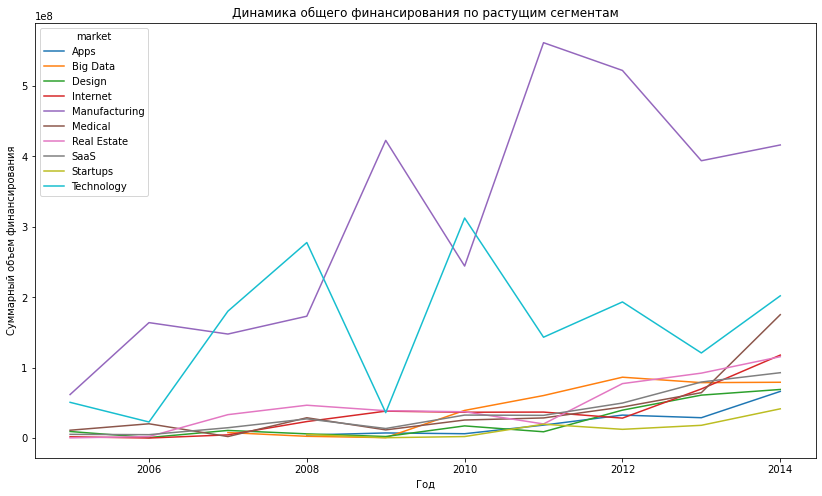

In [ ]:
# Построим график динамики финансирования по растущим сегментам с 2005 года (до этого данных недостаточно)
growing_data[growing_data.index >= 2005].plot(kind = 'line',
                  figsize = (14, 8))

plt.title('Динамика общего финансирования по растущим сегментам')
plt.xlabel('Год')
plt.ylabel('Суммарный объем финансирования')

plt.show()

К 2014 году несколько массовых сегментов демонстрируют устойчивый рост инвестиционной активности.
Наиболее заметный рост наблюдается в сегментах `Internet`, `Medical` и `Apps`, где объемы финансирования значительно увеличиваются в последние годы рассматриваемого периода. Эти сегменты демонстрируют не только рост в 2014 по сравнению с 2013 годом, но и общую положительную динамику в последние годы.

Стабильное увеличение финансирования также наблюдается в сегментах `SaaS`, `Real Estate` и `Technology`, которые имеют более равномерный рост без резких колебаний.

Некоторые сегменты, например `Manufacturing`, показывают значительные объемы инвестиций, однако их динамика менее равномерна и сопровождается заметными колебаниями по годам.

Можно сделать вывод, что наиболее быстрый и уверенный рост демонстрируют сегменты, связанные с развитием цифровых технологий, интернет-сервисов и программных решений. Это отражает усилие интереса инвесторов к технологическим направлениям и цифровой экономике в рассматриваемый период.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Рассчитаем, какую долю от предоставленных средств составляют возвращенные инвестиции.
Сравним суммарный объем финансирования и суммарные возвраты по каждому типу финансирования и каждому году.

In [ ]:
# Посчитаем, сколько денег было выдано по каждому типу финансирования в каждом году
funding_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
funding_by_year = cb_investments.groupby('funding_year')[funding_types].sum()
funding_by_year.head()

,venture,debt_financing,private_equity,seed,angel
funding_year,,,,,
1999.0,76239814.0,350000.0,3000000.0,9540493.0,1200000.0
2000.0,327962152.0,14000000.0,0.0,16759140.0,24086333.0
2001.0,217519117.0,5829217.0,0.0,2667675.0,1000000.0
2002.0,306940622.0,15309671.0,7500000.0,10465192.0,3000000.0
2003.0,372234425.0,1050000.0,0.0,15318355.0,5629661.0


В датасете `cb_returns` значения возвратов хранятся в формате миллионов долларов, а в `cb_investments` суммы финансирования в формате долларов. Приведем данные к одному масштабу. Для более удобного анализа результатов выберем формат миллионов.

In [ ]:
# Изменим разрядность финансирования
funding_by_year = funding_by_year / 1000000
funding_by_year.head()

,venture,debt_financing,private_equity,seed,angel
funding_year,,,,,
1999.0,76.239814,0.350000,3.0,9.540493,1.200000
2000.0,327.962152,14.000000,0.0,16.759140,24.086333
2001.0,217.519117,5.829217,0.0,2.667675,1.000000
2002.0,306.940622,15.309671,7.5,10.465192,3.000000
2003.0,372.234425,1.050000,0.0,15.318355,5.629661


In [ ]:
# Изучим возвраты по годам
returns_by_year = cb_returns[funding_types]
returns_by_year.head()

,venture,debt_financing,private_equity,seed,angel
year,,,,,
2000,55.40,8.66,0.00,16.70,6.43
2001,23.49,4.49,0.00,2.88,1.18
2002,209.42,3.42,1.51,6.59,3.41
2003,233.86,1.09,1.62,7.74,3.41
2004,555.90,13.55,2.19,9.93,9.18


In [ ]:
# Разделим возвраты на объем финансирования
normalized_returns = returns_by_year / (funding_by_year + 1e-60)
normalized_returns.head()

,venture,debt_financing,private_equity,seed,angel
1999.0,NaN,NaN,NaN,NaN,NaN
2000.0,0.168922,0.618571,0.000000e+00,0.996471,0.266956
2001.0,0.107991,0.770258,0.000000e+00,1.079592,1.180000
2002.0,0.682282,0.223388,2.013333e-01,0.629707,1.136667
2003.0,0.628260,1.038095,1.620000e+60,0.505276,0.605720


In [ ]:
# Уберем аномальные значения (показатель возврата больше 1)
normalized_returns[normalized_returns > 1] = None
normalized_returns

,venture,debt_financing,private_equity,seed,angel
1999.0,NaN,NaN,NaN,NaN,NaN
2000.0,0.168922,0.618571,0.000000,0.996471,0.266956
2001.0,0.107991,0.770258,0.000000,NaN,NaN
2002.0,0.682282,0.223388,0.201333,0.629707,NaN
2003.0,0.628260,NaN,NaN,0.505276,0.605720
2004.0,0.837009,0.439698,NaN,0.548476,0.833504
2005.0,0.546586,0.344964,0.480000,0.674695,0.509894
2006.0,0.343678,0.803772,0.935453,0.925372,0.674853
2007.0,0.297243,0.602488,0.579056,0.366153,0.817837
2008.0,0.190873,0.927484,0.679925,0.297083,0.412476


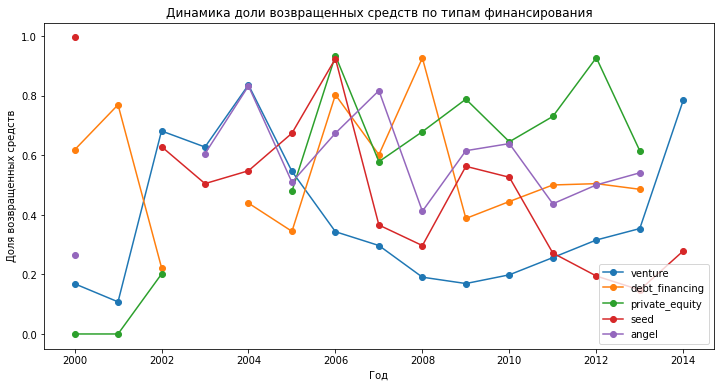

In [ ]:
# Построим график динамики доли возвратов
normalized_returns.plot(figsize = (12, 6),
                       marker = 'o')

plt.title('Динамика доли возвращенных средств по типам финансирования')
plt.xlabel('Год')
plt.ylabel('Доля возвращенных средств')

plt.show()

Эффективность различных типов финансирования со временем изменяется.
Наиболее заметный и относительно устойчивый рост показателя наблюдается в `venture`. Особенно это заметно в последние годы рассматриваемого периода, когда доля возврата для этого типа финансирования увеличивается. Это может свидетельствовать о повышении эффективности вложений и росте зреслости компаний, получающих такие виды финансирования.

Для типов финансирования `debt_financing` и `private equity` дианмика не является устойчиво растущей: значения заметно колеблются по годам. Для этих типов финансирования корректнее сказать о высоких, но волатильных значениях показателя, а не о стабильном росте эффективности.

Для `angel`-инвестиций показатель возврата также демонстрирует умеренный рост, но его динамика более нестабильна и колеблется по годам.

Тип финансирования `seed` показывает наименее устойчивую динамику: после сравнительно высоких значений в начале периода наблюдается постепенное снижение показателя, что может быть связано с более высоким уровнем риска инвестиций на самых ранних стадиях развития компаний.

Анализ динамики финансирования показывает, что инвестиционная активность на рынке стартапов значительно выросла в течении рассматриваемого периода. КОличество раундов финансирования увеличивалось с середины 2000-ых годов и достигло максимума к 2013 году, что говорит о расширении рынка и росте числа компаний, привлекающих инвестиции.

Типичный размер одного раунда финансирования со временем постепенно снижался, что может говорить об увеличении числа ранних инвестиций и появление большого количества стартапов, привлекающих сравнительно небольшие суммы.

Наиболее заметный рост наблюдается в технологических направлениях, что отражает усиление интереса инвесторов к цифровым технологиям, интеренет-сервисам и программным решениям.

Наиболее устойчивый рост эффективности инвестиций наблюдается в типах финансирования venture, debt financing и private equity, которые чаще связаны с более зрелыми компаниями и крупными инвестиционными сделками.

В целом, рынок стартап-инвестиций характеризуется ростом количества сделок, активным развитием технологических сегментов и более высокой эффективностью инвестиций на более поздних стадиях финансирования.

Изменение показателя по категории не однозначно указывает на прямой рост эффективности, а говорит о том, что разные типы финансирования демонстрируют различную динамику возврата, а инвестиции на более поздних стадиях развития компаний чаще сопровождаются более высокими значениями показателя возврата.

Результаты анализа динамики показывают, что инвестиционный рынок активно развивается и всё больше компаний привлекают финансирование, особенно в технологических сегментах. Для инвестора это означает, что наибольший потенциал роста может быть сосредоточен в направлениях, связанных с цифровыми технологиями и интернет-сервисами, где наблюдается устойчивый рост инвестиций и высокая инвестиционная активность.


## Шаг 5. Итоговый вывод и рекомендации

В рамках проекта был проведён анализ данных о финансировании компаний и динамике инвестиционного рынка.
В ходе исследования были выполнены следующие этапы:
- проведена предобработка данных: исправлены типы данных, обработаны пропуски, удалены дубликаты и аномальные значения финансирования
- сформированы дополнительные признаки, позволяющие анализировать длительность финансирования компаний и структуру сегментов рынка
- проведён анализ типов финансирования по объёму инвестиций, популярности и объёму возвратов
- изучена динамика инвестиционной активности по годам
- выявлены сегменты рынка, демонстрирующие рост суммарного объёма финансирования
- рассчитана доля возвращённых средств по различным типам финансирования

## Основные результаты анализа
Анализ показал, что инвестиционная активность на рынке стартапов значительно выросла в течение рассматриваемого периода. Количество раундов финансирования стабильно увеличивалось с середины 2000-х годов и достигло максимума к 2013 году.

При этом типичный размер одного раунда финансирования постепенно снижался, что может указывать на рост числа ранних инвестиций и увеличение количества компаний, находящихся на начальных стадиях развития.

Исследование структуры сегментов рынка показало, что значительная часть направлений относится к нишевым сегментам, однако основная инвестиционная активность сосредоточена в массовых сегментах рынка.

Наиболее заметный рост объёмов финансирования наблюдается в сегментах, связанных с цифровыми технологиями и интернет-сервисами, включая Internet, Apps, SaaS, Technology и Medical.

Анализ типов финансирования показал, что наиболее распространённым инструментом инвестирования является venture-финансирование, которое также привлекает наибольший объём капитала и демонстрирует наибольшие суммарные возвраты средств.

## Рекомендации для инвестора (на 2015 год)
На основании проведённого анализа можно предположить, что наиболее перспективными направлениями для инвестиций являются сегменты, связанные с цифровыми технологиями и интернет-сервисами, в частности:
- Internet
- Apps
- SaaS
- Technology

Эти сегменты демонстрируют устойчивый рост объёмов финансирования и высокий интерес со стороны инвесторов.

С точки зрения инструментов финансирования наиболее уместным типом инвестиций может быть venture-финансирование, поскольку:
- этот тип инвестирования используется наиболее широко
- он сопровождается крупнейшими объёмами привлечённых средств
- он демонстрирует значительные объёмы возврата капитала

Следует учитывать, что данные за 2014 год могут быть неполными, поскольку количество раундов финансирования в этом году заметно ниже по сравнению с 2013 годом. Это может влиять на интерпретацию динамики последних лет.

Кроме того, анализ основан на агрегированных данных по сегментам рынка и типам финансирования, поэтому отдельные компании или специфические инвестиционные сделки могут отклоняться от выявленных общих тенденций.

## Общий вывод
В целом результаты анализа согласуются между собой: наиболее активный рост инвестиций наблюдается в технологических сегментах рынка, а ключевым инструментом инвестирования остаётся венчурное финансирование.

Это позволяет предположить, что в ближайшие годы основная инвестиционная активность будет продолжать концентрироваться в технологических направлениях и интернет-сервисах, где сохраняется высокий потенциал роста и масштабирования бизнеса.